In [60]:
import pandas as pd
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt #Plotting properties
import seaborn as sns #Plotting properties
from sklearn.model_selection import train_test_split #Data testing
from sklearn.linear_model import LogisticRegression #Prediction Model
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, r2_score, roc_curve, roc_auc_score, precision_recall_curve, average_precision_score
from sklearn.preprocessing import LabelEncoder #Variable encoding and decoding for XGBoost
import category_encoders as ce
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from skopt import BayesSearchCV
from skopt.space import Integer, Categorical
import time

import statsmodels.api as sm
from statsmodels.genmod.generalized_linear_model import GLM

# 📺 Predicción de Churn Voluntario Premium

## Contexto y Variables Principales

Los datos utilizados en este cuaderno provienen del sector de telecomunicaciones y entretenimiento digital. Cada registro corresponde a un cliente con características asociadas a su comportamiento de uso y relación con la compañía. Se incluye información demográfica básica 🌍 (país, región), variables contractuales 📜 (método de pago, antigüedad del cliente, producto contratado), y consumo de servicios premium 🎬⚽ (movies, fútbol, adultos, otros).

Adicionalmente, se registran métricas de interacción con la compañía 📞 (llamadas entrantes y salientes), órdenes de trabajo gestionadas 🔧 y señales de insatisfacción como intenciones de baja o cancelaciones reincidentes ⚠️. También se consideran indicadores de valor futuro del cliente 💰 y segmentación CLTV, que ayudan a proyectar la relevancia de cada usuario dentro del negocio.

El objetivo principal es predecir la variable TARGET, que indica si un cliente realizará un churn voluntario premium (abandono del servicio de manera voluntaria). Este tipo de análisis resulta esencial para las empresas, ya que permite diseñar estrategias de retención más efectivas, identificar perfiles de riesgo y optimizar recursos destinados a la fidelización de clientes.

| Variables                   | Descripción                                      |
|-----------------------------|--------------------------------------------------|
| MES                         | Variable Año / Mes Corte                         |
| COD_PAIS                    | País                                             |
| CLASE                       | Variable Regional Speed Test                     |
| CUSTOMER_ID                 | ID                                               |
| MOP                         | Método de Pago                                   |
| AGRUP_BASICO                | Producto Clásico                                 |
| CANT_PREMIUM                | Cantidad Total Productos Premium Contratados     |
| CANT_MOVIES                 | Cantidad Premium Movies Contratados              |
| CANT_FUTBOL                  | Cantidad Premium Futbol Contratados              |
| CANT_ADULTOS                | Cantidad Premium Adultos Contratados             |
| CANT_OTRO_PREMIUM           | Cantidad Premium Otros Contratados               |
| CANT_FUTBOL_LOCAL           | Cantidad Premium Futbol Local Contratados        |
| WO                          | Numero Ordenes de Trabajo                        |
| TELEFONO_IN                 | Numero llamadas del cliente en el mes            |
| TELEFONO_OUT                | Numero llamadas al cliente en el mes             |
| INTENCIONES_BAJA            | Intenciones Cancelación                          |
| INTENCIONES_BAJA_REINCIDENTES | Intenciones Cancelación reincidentes           |
| RANGO_ANTIGUEDAD            | Rango Antigüedad Total Cliente                   |
| CFV                         | Valor Futuro del cliente                         |
| TECNOLOGIA                  | Tecnología                                       |
| ANTIGÜEDAD                  | Antigüedad Total Cliente                         |
| CLTV_NEW                    | Segmento CLTV                                    |
| TARGET                      | Variable Objetivo Churn Voluntario Premium       |


# Carga de datos

In [22]:
pd.set_option('display.max_columns', None)

In [23]:
df = pd.read_csv('BASE_MODELO_VOLUNTARIO.csv', sep=';')
df.head()

,MES,COD_PAIS,CLASE,CUSTOMER_ID,MOP,AGRUP_BASICO,CANT_PREMIUM,CANT_MOVIES,CANT_FUTBOL,CANT_ADULTOS,CANT_OTRO_PREMIUM,CANT_FUTBOL_LOCAL,WO,TELEFONO_IN,TELEFONO_OUT,INTENCIONES_BAJA,INTENCIONES_BAJA_REINCIDENTES,RANGO_ANTIGUEDAD,CLTV,TECNOLOGIA,ANTIGUEDAD,CLTV_NEW,TARGET
0,201811,EC,WHITE,1,Tarjeta de Credito,ORO,2,2,0,0,0,0,0,4,0,0,0,+24,7418.160956,NEXUS,43,3.High,0
1,201811,EC,GREY,4,Debito Bancario,ORO,1,1,0,0,0,0,0,0,0,0,0,+24,2003.364155,IRD,72,3.High,0
2,201810,EC,GREY,5,Tarjeta de Credito,ORO,1,1,0,0,0,0,0,0,0,0,0,+24,4077.205858,IRD HD DVR,108,3.High,0
3,201812,EC,GREY,6,Debito Bancario,BRONCE,1,1,0,0,0,0,0,0,0,0,0,+24,-425.743249,IRD HD,41,0.Negativo,1
4,201811,EC,WHITE,7,Tarjeta de Credito,PLATA,2,2,0,0,0,0,0,1,0,0,0,+24,3315.075786,IRD HD DVR,46,3.High,0


In [24]:
df = df.set_index(['MES', 'COD_PAIS', 'CUSTOMER_ID'])
df.head()

CLASE                 MOP AGRUP_BASICO  \
MES    COD_PAIS CUSTOMER_ID                                           
201811 EC       1            WHITE  Tarjeta de Credito          ORO   
                4             GREY     Debito Bancario          ORO   
201810 EC       5             GREY  Tarjeta de Credito          ORO   
201812 EC       6             GREY     Debito Bancario       BRONCE   
201811 EC       7            WHITE  Tarjeta de Credito        PLATA   

                             CANT_PREMIUM  CANT_MOVIES  CANT_FUTBOL  \
MES    COD_PAIS CUSTOMER_ID                                           
201811 EC       1                       2            2            0   
                4                       1            1            0   
201810 EC       5                       1            1            0   
201812 EC       6                       1            1            0   
201811 EC       7                       2            2            0   

                             CANT_ADULTOS  CANT_OTRO_PREMIUM  \
MES    COD_PAIS CUSTOMER_ID                                    
201811 EC       1                       0                  0   
                4                       0                  0   
201810 EC       5                       0                  0   
201812 EC       6                       0                  0   
201811 EC       7                       0                  0   

                             CANT_FUTBOL_LOCAL  WO  TELEFONO_IN  TELEFONO_OUT  \
MES    COD_PAIS CUSTOMER_ID                                                     
201811 EC       1                            0   0            4             0   
                4                            0   0            0             0   
201810 EC       5                            0   0            0             0   
201812 EC       6                            0   0            0             0   
201811 EC       7                            0   0            1             0   

                             INTENCIONES_BAJA  INTENCIONES_BAJA_REINCIDENTES  \
MES    COD_PAIS CUSTOMER_ID                                                    
201811 EC       1                           0                              0   
                4                           0                              0   
201810 EC       5                           0                              0   
201812 EC       6                           0                              0   
201811 EC       7                           0                              0   

                            RANGO_ANTIGUEDAD         CLTV  TECNOLOGIA  \
MES    COD_PAIS CUSTOMER_ID                                             
201811 EC       1                        +24  7418.160956       NEXUS   
                4                        +24  2003.364155         IRD   
201810 EC       5                        +24  4077.205858  IRD HD DVR   
201812 EC       6                        +24  -425.743249      IRD HD   
201811 EC       7                        +24  3315.075786  IRD HD DVR   

                             ANTIGUEDAD    CLTV_NEW  TARGET  
MES    COD_PAIS CUSTOMER_ID                                  
201811 EC       1                    43      3.High       0  
                4                    72      3.High       0  
201810 EC       5                   108      3.High       0  
201812 EC       6                    41  0.Negativo       1  
201811 EC       7                    46      3.High       0

# ¿Qué son los hiperparámetros? 🤖⚙️

Los hiperparámetros son “perillas” que tú ajustas antes de entrenar un modelo (no se aprenden de los datos).
Controlan cosas como: qué tan complejo puede ser el modelo, qué tan rápido aprende, cuánta regularización aplica, o qué optimizador usa.

Diferencia clave:
 - **Parámetros del modelo** (p. ej., $\beta$'s de un modelo de regresión) se aprenden durante el entrenamiento.
 - **Hiperparámetros** (p. ej., learning_rate, n_estimators) los defines tú y permanecen fijos durante ese entrenamiento.


## Analogía 🍪

Hornear galletas. La receta (modelo) se “ajusta” con el tiempo de horno y la temperatura (hiperparámetros). Si te pasas, se queman (sobreajuste); si te quedas corto, quedan crudas (subajuste).

# ¿Por qué hacer hyperparameter tuning? 🎯

 - Rendimiento: Cambiar la “perilla” correcta puede subir mucho la exactitud/F1/AUC.

 - Evitar bajo/sobreajuste: Ajustas la complejidad para no quedarte corto ni pasarte.

 - Generalización: Un buen set de hiperparámetros funciona bien en datos nuevos.

 - Eficiencia: Buscar “a ciegas” quema cómputo 💸. Un tuning ordenado ahorra tiempo y dinero.

 - Mejora iterativa: Es un proceso cíclico: probar → evaluar → refinar.

# Hiperparámetros comunes (por familia) 🧰

1. **Regresión/Clasificación lineal y regularizada**

 - C (Logistic/SVM lineal): inverso de la regularización (bajo C ⇒ más regularización).

 - alpha (Lasso/Ridge/ElasticNet): fuerza de regularización.

 - l1_ratio (ElasticNet): mezcla L1/L2.




2. Aboles/Ensamblados (RandomForest, GBM, XGBoost, LightGBM, CatBoost)

 - n_estimators: número de árboles.

 - max_depth, min_samples_leaf, min_child_weight: controlan complejidad.

 - max_features/colsample_bytree: columnas por split/árbol.



3. SVM

 - kernel (lineal, rbf, polinomial)

 - C (margen vs. error)

 - gamma (RBF): alcance de la influencia de puntos (usa búsqueda en escala logarítmica).




4. Redes Neuronales

 - learning_rate, batch_size, optimizer (Adam, SGD…),

 - Arquitectura: #capas, #neuronas por capa, dropout, activaciones (ReLU, tanh…).

 - weight_decay (regularización L2).

 - Estrategias: early_stopping, patience, lr_scheduler.




5. Datos categóricos

 - Estrategia de codificación: one-hot, target encoding, hashing (elige según modelo/escala).

## ⚙️ Random Forest para los datos de churn

In [25]:
df['TARGET'].value_counts(), df['TARGET'].value_counts(normalize=True)

(TARGET
 0    39858
 1     3762
 Name: count, dtype: int64,
 TARGET
 0    0.913755
 1    0.086245
 Name: proportion, dtype: float64)

## Pre-procesamiento

In [26]:
df_numericas = df.select_dtypes(include=[np.number]).columns
df_caracter = df.select_dtypes(include=['object']).columns

In [27]:
df_numericas, df_caracter

(Index(['CANT_PREMIUM', 'CANT_MOVIES', 'CANT_FUTBOL', 'CANT_ADULTOS',
        'CANT_OTRO_PREMIUM', 'CANT_FUTBOL_LOCAL', 'WO', 'TELEFONO_IN',
        'TELEFONO_OUT', 'INTENCIONES_BAJA', 'INTENCIONES_BAJA_REINCIDENTES',
        'CLTV', 'ANTIGUEDAD', 'TARGET'],
       dtype='object'),
 Index(['CLASE', 'MOP', 'AGRUP_BASICO', 'RANGO_ANTIGUEDAD', 'TECNOLOGIA',
        'CLTV_NEW'],
       dtype='object'))

In [28]:
encoder = ce.OneHotEncoder(cols=list(df_caracter), use_cat_names=True)
df_encoded = encoder.fit_transform(df)

df_encoded.head()

CLASE_WHITE  CLASE_GREY  CLASE_BLACK  \
MES    COD_PAIS CUSTOMER_ID                                         
201811 EC       1                      1           0            0   
                4                      0           1            0   
201810 EC       5                      0           1            0   
201812 EC       6                      0           1            0   
201811 EC       7                      1           0            0   

                             CLASE_Without Testers  MOP_Tarjeta de Credito  \
MES    COD_PAIS CUSTOMER_ID                                                  
201811 EC       1                                0                       1   
                4                                0                       0   
201810 EC       5                                0                       1   
201812 EC       6                                0                       0   
201811 EC       7                                0                       1   

                             MOP_Debito Bancario  AGRUP_BASICO_ORO  \
MES    COD_PAIS CUSTOMER_ID                                          
201811 EC       1                              0                 1   
                4                              1                 1   
201810 EC       5                              0                 1   
201812 EC       6                              1                 0   
201811 EC       7                              0                 0   

                             AGRUP_BASICO_BRONCE  AGRUP_BASICO_PLATA  \
MES    COD_PAIS CUSTOMER_ID                                            
201811 EC       1                              0                   0   
                4                              0                   0   
201810 EC       5                              0                   0   
201812 EC       6                              1                   0   
201811 EC       7                              0                   1   

                             CANT_PREMIUM  CANT_MOVIES  CANT_FUTBOL  \
MES    COD_PAIS CUSTOMER_ID                                           
201811 EC       1                       2            2            0   
                4                       1            1            0   
201810 EC       5                       1            1            0   
201812 EC       6                       1            1            0   
201811 EC       7                       2            2            0   

                             CANT_ADULTOS  CANT_OTRO_PREMIUM  \
MES    COD_PAIS CUSTOMER_ID                                    
201811 EC       1                       0                  0   
                4                       0                  0   
201810 EC       5                       0                  0   
201812 EC       6                       0                  0   
201811 EC       7                       0                  0   

                             CANT_FUTBOL_LOCAL  WO  TELEFONO_IN  TELEFONO_OUT  \
MES    COD_PAIS CUSTOMER_ID                                                     
201811 EC       1                            0   0            4             0   
                4                            0   0            0             0   
201810 EC       5                            0   0            0             0   
201812 EC       6                            0   0            0             0   
201811 EC       7                            0   0            1             0   

                             INTENCIONES_BAJA  INTENCIONES_BAJA_REINCIDENTES  \
MES    COD_PAIS CUSTOMER_ID                                                    
201811 EC       1                           0                              0   
                4                           0                              0   
201810 EC       5                           0                              0   
201812 EC       6                           0                              0   
201811 

In [29]:
X = df_encoded.drop(columns=['TARGET'])
y = df_encoded['TARGET']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

print('Observaciones en entrenamiento: {}'.format(len(X_train)))
print('Observaciones en Test: {}'.format(len(X_test)))

Observaciones en entrenamiento: 34896
Observaciones en Test: 8724


# Validación Cruzada

Antes de hablar de la optimziación de hiperparámetros es necesario entender el concepto de validación cruzada:

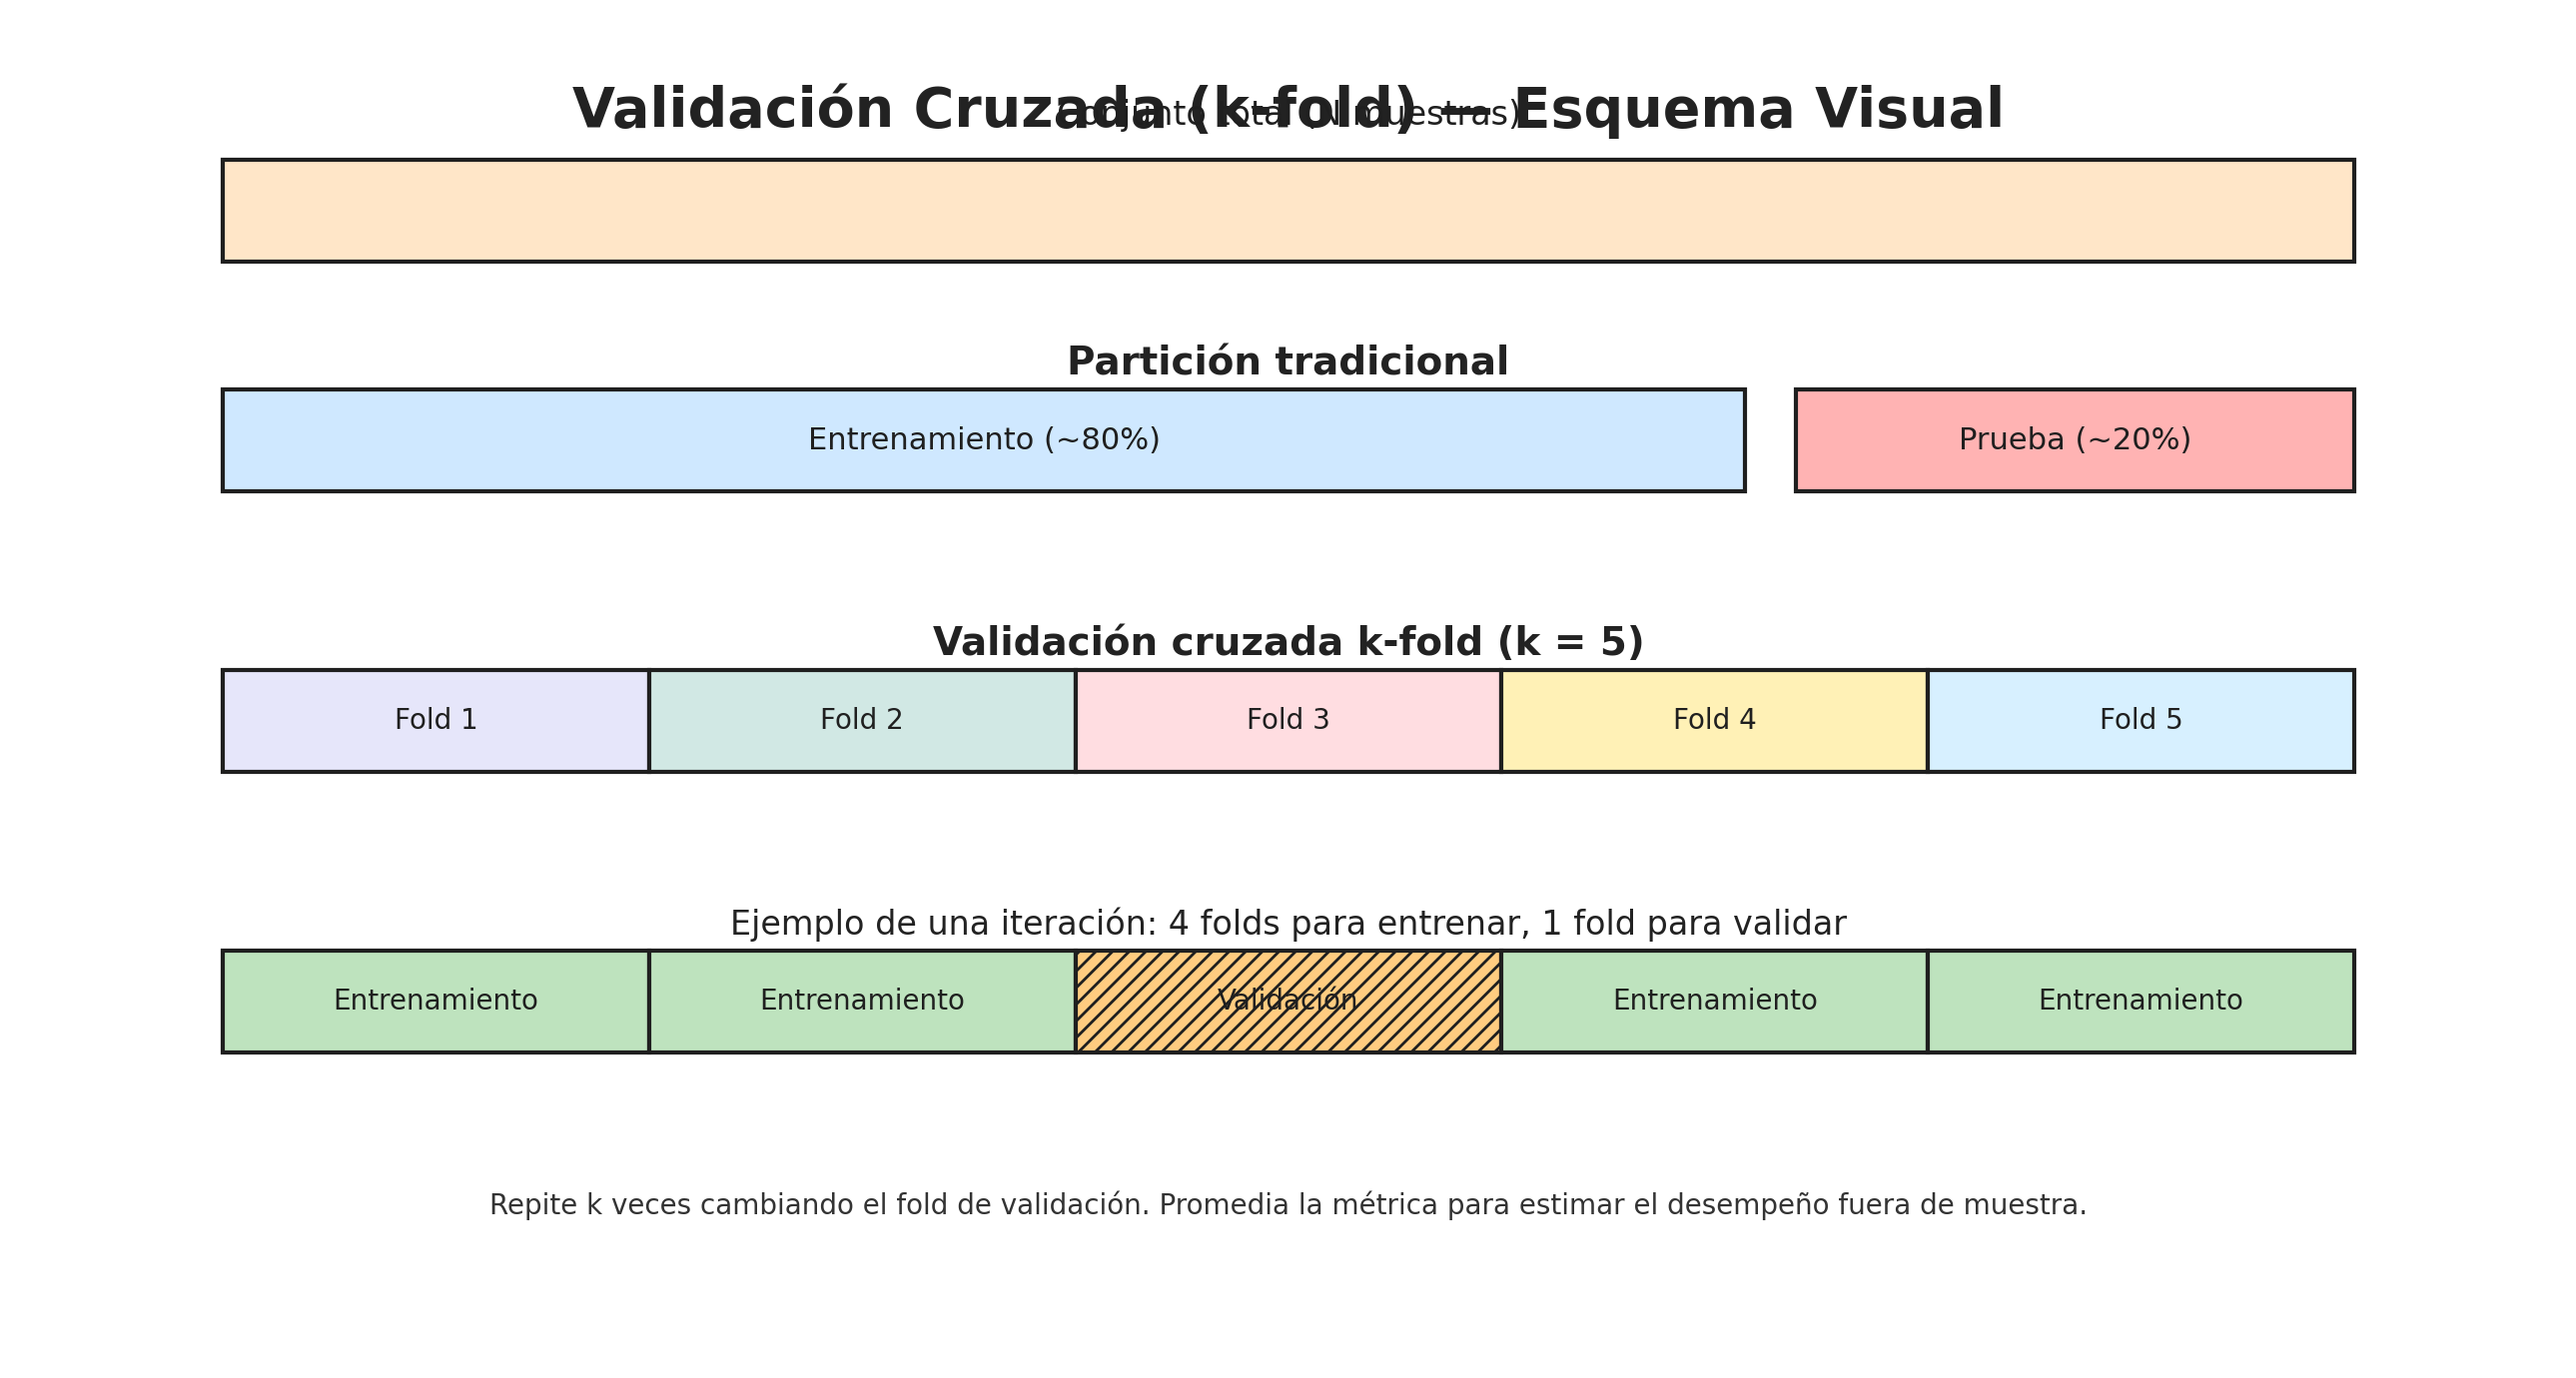

Es un método para estimar el desempeño real de un modelo usando todo el dataset de forma más eficiente que un único train/test split.

## Cómo funciona (k-fold):

 - Divides los datos en k partes iguales (“folds”).

 - Repites k veces: entrenas en k−1 folds y validas en el fold restante.

 - Promedias la métrica (AUC, F1, RMSE, etc.) de las k iteraciones → estimación más estable y con menor varianza. ✅

Ventajas: mejor uso de datos, evaluación más robusta, menos sensibilidad a una partición “suerte”

In [31]:
?RandomForestClassifier

Init signature:
RandomForestClassifier(
    n_estimators=100,
    *,
    criterion='gini',
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    min_weight_fraction_leaf=0.0,
    max_features='sqrt',
    max_leaf_nodes=None,
    min_impurity_decrease=0.0,
    bootstrap=True,
    oob_score=False,
    n_jobs=None,
    random_state=None,
    verbose=0,
    warm_start=False,
    class_weight=None,
    ccp_alpha=0.0,
    max_samples=None,
    monotonic_cst=None,
)
Docstring:     
A random forest classifier.

A random forest is a meta estimator that fits a number of decision tree
classifiers on various sub-samples of the dataset and uses averaging to
improve the predictive accuracy and control over-fitting.
Trees in the forest use the best split strategy, i.e. equivalent to passing
`splitter="best"` to the underlying :class:`~sklearn.tree.DecisionTreeClassifier`.
The sub-sample size is controlled with the `max_samples` parameter if
`bootstrap=True` (default), otherwise the

In [32]:
rf = RandomForestClassifier()
rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [35]:
# --- 2) Predecir ---
y_pred = rf.predict(X_test)

# --- 3) Métricas básicas ---
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification report:\n", classification_report(y_test, y_pred))


Accuracy: 0.921939477303989

Classification report:
               precision    recall  f1-score   support

           0       0.93      0.99      0.96      7958
           1       0.69      0.20      0.31       766

    accuracy                           0.92      8724
   macro avg       0.81      0.60      0.64      8724
weighted avg       0.91      0.92      0.90      8724



In [36]:
confusion_matrix(y_test, y_pred)

array([[7888,   70],
       [ 611,  155]])

In [37]:
y_proba = rf.predict_proba(X_test)[:, 1]  # Probabilidades de la clase positiva

Umbral (Youden J): 0.1000
Umbral (Dist. a (0,1) mínima): 0.0700
Umbral (mejor F1 en PR): 0.3400


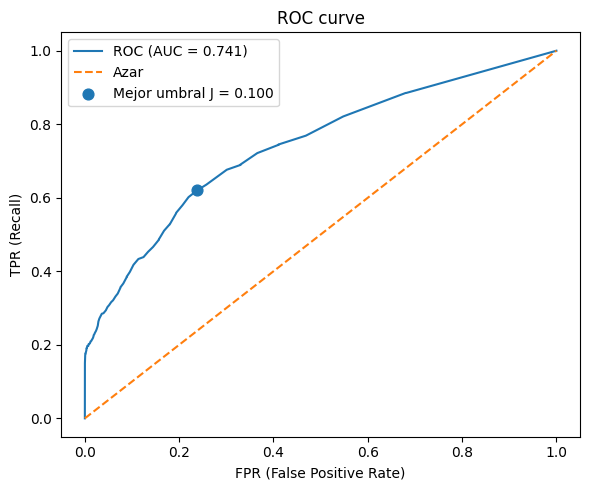

In [38]:
# Calcula ROC y AUC
fpr, tpr, thr_roc = roc_curve(y_test, y_proba)  # guarda thresholds
auc_roc = roc_auc_score(y_test, y_proba)

# (A) Mejor umbral por Youden's J = TPR - FPR
youden = tpr - fpr
idx_j = np.argmax(youden)
thr_j = thr_roc[idx_j]
fpr_j, tpr_j = fpr[idx_j], tpr[idx_j]

# (B) (Opcional) Menor distancia a (0,1)
dist = np.sqrt((fpr - 0)**2 + (tpr - 1)**2)
idx_d = np.argmin(dist)
thr_d = thr_roc[idx_d]
fpr_d, tpr_d = fpr[idx_d], tpr[idx_d]

# (C) (Opcional) Mejor F1 en curva PR (útil si la positiva es rara)
prec, rec, thr_pr = precision_recall_curve(y_test, y_proba)
f1s = 2 * (prec * rec) / (prec + rec + 1e-12)
idx_f1 = np.nanargmax(f1s[:-1])  # el último punto no tiene umbral
thr_f1 = thr_pr[idx_f1]

print(f"Umbral (Youden J): {thr_j:.4f}")
print(f"Umbral (Dist. a (0,1) mínima): {thr_d:.4f}")
print(f"Umbral (mejor F1 en PR): {thr_f1:.4f}")

# --- Plot ROC con el punto del mejor umbral (Youden J) ---
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"ROC (AUC = {auc_roc:.3f})")
plt.plot([0,1], [0,1], linestyle="--", label="Azar")

# Marca el mejor punto (Youden J)
plt.scatter([fpr_j], [tpr_j], s=60, marker='o',
            label=f"Mejor umbral J = {thr_j:.3f}")

# (Opcional) marca el de mínima distancia
# plt.scatter([fpr_d], [tpr_d], s=60, marker='s',
#             label=f"Min dist (thr={thr_d:.3f})")

plt.xlabel("FPR (False Positive Rate)")
plt.ylabel("TPR (Recall)")
plt.title("ROC curve")
plt.legend()
plt.tight_layout()
plt.show()

Mejor umbral (F1 máx): 0.3400
Precision=0.433  Recall=0.285  F1=0.343
Average Precision (AP): 0.374


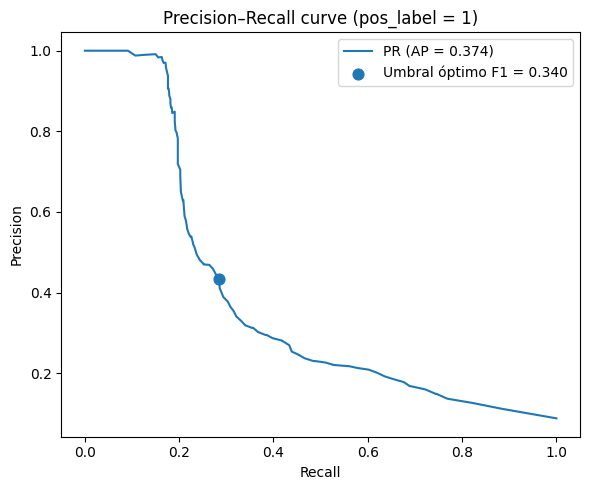

In [39]:
pos_label = rf.classes_[1]

# Curva PR (nota: len(thr_pr) = len(prec) - 1)
prec, rec, thr_pr = precision_recall_curve(y_test, y_proba)
ap = average_precision_score(y_test, y_proba)

# F1 en cada punto de la curva (el último punto no tiene umbral)
f1s = 2 * (prec * rec) / (prec + rec + 1e-12)
best_idx = np.nanargmax(f1s[:-1])      # evitar el último punto sin umbral
best_thr = thr_pr[best_idx]
best_prec = prec[best_idx]
best_rec = rec[best_idx]
best_f1 = f1s[best_idx]

print(f"Mejor umbral (F1 máx): {best_thr:.4f}")
print(f"Precision={best_prec:.3f}  Recall={best_rec:.3f}  F1={best_f1:.3f}")
print(f"Average Precision (AP): {ap:.3f}")

# Predicciones con el mejor umbral (si quieres usarlas)
y_pred_best = (y_proba >= best_thr).astype(int)

# --- Plot PR con el punto óptimo ---
plt.figure(figsize=(6,5))
plt.plot(rec, prec, label=f"PR (AP = {ap:.3f})")
plt.scatter([best_rec], [best_prec], s=60, marker='o',
            label=f"Umbral óptimo F1 = {best_thr:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Precision–Recall curve (pos_label = {pos_label})")
plt.legend()
plt.tight_layout()
plt.show()

In [40]:
# --- 1) Usa el umbral óptimo que ya calculaste ---
thr_opt = best_thr   # p.ej., el que maximizó F1 en la curva PR

# --- 2) Probabilidades para la clase positiva ---
pos_label = rf.classes_[1]
neg_label = rf.classes_[0]
pos_idx = list(rf.classes_).index(pos_label)

y_proba = rf.predict_proba(X_test)[:, pos_idx]

# --- 3) Predicción con umbral custom ---
y_pred_thr = np.where(y_proba >= thr_opt, pos_label, neg_label)

# --- 4) Métricas con el nuevo umbral ---
print("Accuracy:", accuracy_score(y_test, y_pred_thr))
print("\nClassification report (umbral óptimo):\n",
      classification_report(y_test, y_pred_thr))

Accuracy: 0.9044016506189821

Classification report (umbral óptimo):
               precision    recall  f1-score   support

           0       0.93      0.96      0.95      7958
           1       0.43      0.28      0.34       766

    accuracy                           0.90      8724
   macro avg       0.68      0.62      0.65      8724
weighted avg       0.89      0.90      0.90      8724



____________________

# Técnicas para ajustar hiperparámetros 🧪

## Grid Search 🗺️

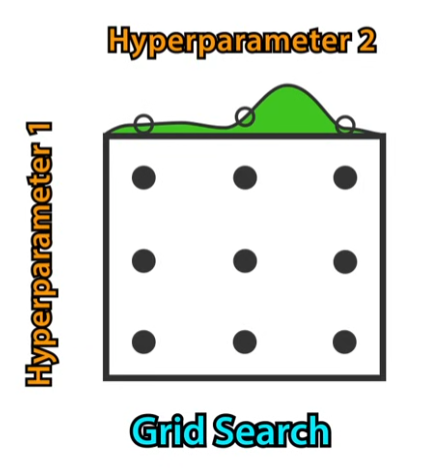


Grid Search 🗺️
Explora todas las combinaciones de una grilla:

 - Simple y reproducible.
 - Caro (explota combinatorialmente), ineficiente en espacios grandes.

In [41]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'bootstrap': [True, False]
}

In [45]:
t0 = time.perf_counter()

grid_search = GridSearchCV(
    RandomForestClassifier(),
    param_grid=param_grid,
    cv=5,
    scoring="roc_auc", 
    n_jobs=-1,        # opcional: paraleliza
    verbose=1         # opcional: log
)
grid_search.fit(X_train, y_train)

elapsed = time.perf_counter() - t0
print(f"Tiempo total GridSearchCV: {elapsed:.2f} s")
print("Best Parameters:", grid_search.best_params_)
print("Best Estimator:", grid_search.best_estimator_)

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Tiempo total GridSearchCV: 82.54 s
Best Parameters: {'bootstrap': False, 'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Best Estimator: RandomForestClassifier(bootstrap=False, max_depth=10, n_estimators=200)


Umbral (Youden J): 0.1052
Umbral (Dist. a (0,1) mínima): 0.0823
Umbral (mejor F1 en PR): 0.1728


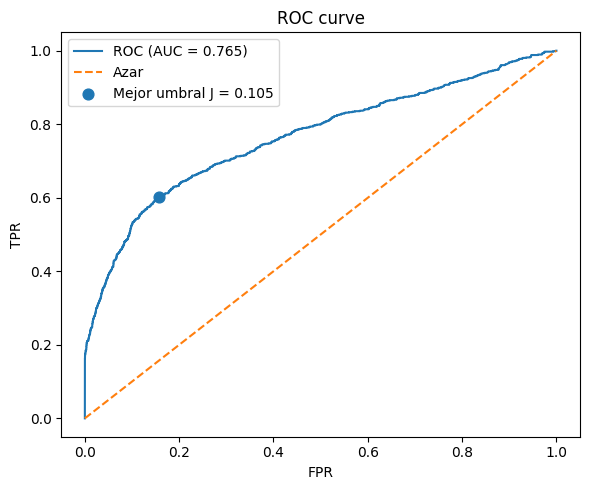

In [46]:
best_model = grid_search.best_estimator_   # ya viene reentrenado (refit=True por defecto)

y_proba = best_model.predict_proba(X_test)[:, 1]

# 3) Tu código para elegir umbrales y graficar ROC
fpr, tpr, thr_roc = roc_curve(y_test, y_proba)
auc_roc = roc_auc_score(y_test, y_proba)

youden = tpr - fpr
idx_j = np.argmax(youden)
thr_j = thr_roc[idx_j]
fpr_j, tpr_j = fpr[idx_j], tpr[idx_j]

dist = np.sqrt((fpr - 0)**2 + (tpr - 1)**2)
idx_d = np.argmin(dist)
thr_d = thr_roc[idx_d]

prec, rec, thr_pr = precision_recall_curve(y_test, y_proba)
f1s = 2 * (prec * rec) / (prec + rec + 1e-12)
idx_f1 = np.nanargmax(f1s[:-1])
thr_f1 = thr_pr[idx_f1]

print(f"Umbral (Youden J): {thr_j:.4f}")
print(f"Umbral (Dist. a (0,1) mínima): {thr_d:.4f}")
print(f"Umbral (mejor F1 en PR): {thr_f1:.4f}")

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"ROC (AUC = {auc_roc:.3f})")
plt.plot([0,1], [0,1], "--", label="Azar")
plt.scatter([fpr_j], [tpr_j], s=60, label=f"Mejor umbral J = {thr_j:.3f}")
plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title("ROC curve"); plt.legend(); plt.tight_layout(); plt.show()

## Random Search 🎲

Muestra al azar desde distribuciones (¡usa escalas logarítmicas p. ej. 10^[−4, −1] para lr!).

Mucho más eficiente que grid en alta dimensión.

Suele encontrar buenos resultados rápido.
 - No usa la “historia” de evaluaciones.

In [50]:
from scipy.stats import randint
param_dist = {
    "n_estimators": randint(100, 200),
    "max_depth": randint(4, 20),
    "min_samples_leaf": randint(1, 10),
    "max_features": ["sqrt", "log2", None],
}

In [51]:
t0 = time.perf_counter()

grid_search = RandomizedSearchCV(
    RandomForestClassifier(),
    param_dist,
    n_iter=40,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)
grid_search.fit(X_train, y_train)

elapsed = time.perf_counter() - t0
print(f"Tiempo total GridSearchCV: {elapsed:.2f} s")
print("Best Parameters:", grid_search.best_params_)
print("Best Estimator:", grid_search.best_estimator_)


Fitting 5 folds for each of 40 candidates, totalling 200 fits
Tiempo total GridSearchCV: 118.84 s
Best Parameters: {'max_depth': 13, 'max_features': 'log2', 'min_samples_leaf': 9, 'n_estimators': 159}
Best Estimator: RandomForestClassifier(max_depth=13, max_features='log2', min_samples_leaf=9,
                       n_estimators=159)


Umbral (Youden J): 0.1216
Umbral (Dist. a (0,1) mínima): 0.0817
Umbral (mejor F1 en PR): 0.1716


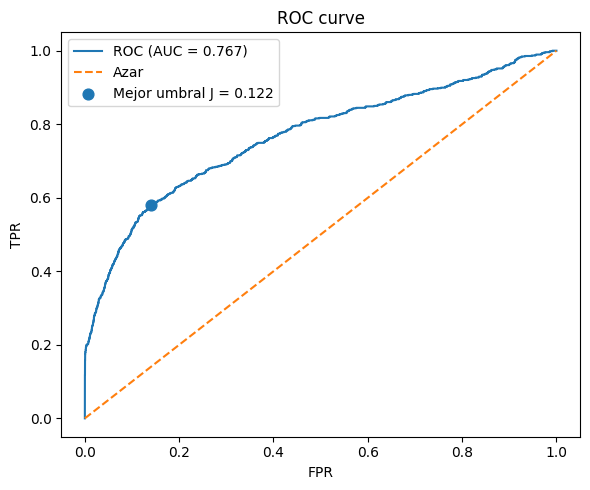

In [52]:
best_model = grid_search.best_estimator_   # ya viene reentrenado (refit=True por defecto)

y_proba = best_model.predict_proba(X_test)[:, 1]

# 3) Tu código para elegir umbrales y graficar ROC
fpr, tpr, thr_roc = roc_curve(y_test, y_proba)
auc_roc = roc_auc_score(y_test, y_proba)

youden = tpr - fpr
idx_j = np.argmax(youden)
thr_j = thr_roc[idx_j]
fpr_j, tpr_j = fpr[idx_j], tpr[idx_j]

dist = np.sqrt((fpr - 0)**2 + (tpr - 1)**2)
idx_d = np.argmin(dist)
thr_d = thr_roc[idx_d]

prec, rec, thr_pr = precision_recall_curve(y_test, y_proba)
f1s = 2 * (prec * rec) / (prec + rec + 1e-12)
idx_f1 = np.nanargmax(f1s[:-1])
thr_f1 = thr_pr[idx_f1]

print(f"Umbral (Youden J): {thr_j:.4f}")
print(f"Umbral (Dist. a (0,1) mínima): {thr_d:.4f}")
print(f"Umbral (mejor F1 en PR): {thr_f1:.4f}")

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"ROC (AUC = {auc_roc:.3f})")
plt.plot([0,1], [0,1], "--", label="Azar")
plt.scatter([fpr_j], [tpr_j], s=60, label=f"Mejor umbral J = {thr_j:.3f}")
plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title("ROC curve"); plt.legend(); plt.tight_layout(); plt.show()

## Optimización Bayesiana 🧠

Modela la función “hiperparámetros → métrica” y elige el próximo punto de forma inteligente.

Converge con menos evaluaciones.

Ideal cuando entrenar es costoso.
− Implementación un poco más compleja.

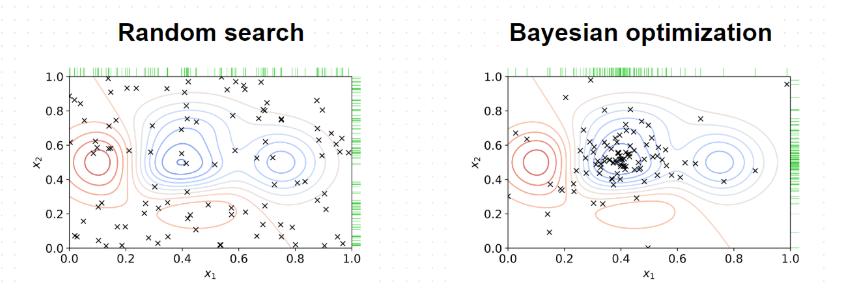

In [59]:
search_spaces = {
    "n_estimators":     Integer(100, 200),
    "max_depth":        Integer(4, 20),
    "min_samples_leaf": Integer(1, 10),
    "max_features":     Categorical(["sqrt", "log2", None]),
}


In [61]:
# 2) Configuración del CV (estratificado para clasificación)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [62]:

# 3) BayesSearchCV (optimización bayesiana)
t0 = time.perf_counter()
bayes_search = BayesSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    search_spaces=search_spaces,
    n_iter=40,                 # nº de evaluaciones (análoga a n_iter de RandomizedSearchCV)
    cv=cv5,
    scoring="roc_auc",
    n_jobs=-1,
    refit=True,
    random_state=42,
    verbose=1
)
bayes_search.fit(X_train, y_train)

elapsed = time.perf_counter() - t0
print(f"Tiempo total BayesSearchCV: {elapsed:.2f} s")
print("Best Parameters:", bayes_search.best_params_)
print("Best Estimator:", bayes_search.best_estimator_)
print("CV best score (mean ROC AUC):", bayes_search.best_score_)

Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fi

Umbral (Youden J): 0.1087
Umbral (Dist. a (0,1) mínima): 0.0886
Umbral (mejor F1 en PR): 0.1816


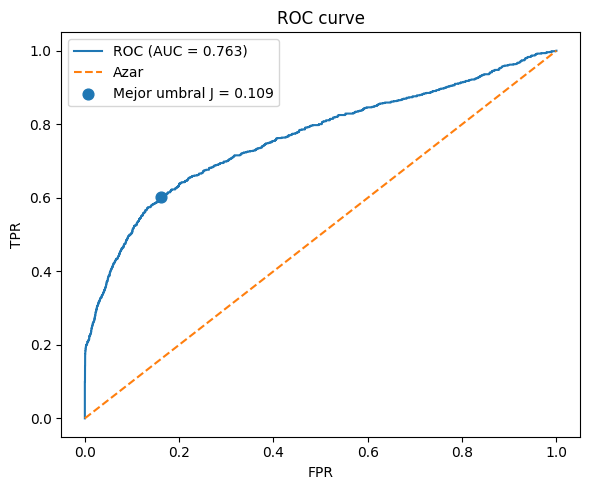

In [63]:
best_model = bayes_search.best_estimator_   # ya viene reentrenado (refit=True por defecto)

y_proba = best_model.predict_proba(X_test)[:, 1]

# 3) Tu código para elegir umbrales y graficar ROC
fpr, tpr, thr_roc = roc_curve(y_test, y_proba)
auc_roc = roc_auc_score(y_test, y_proba)

youden = tpr - fpr
idx_j = np.argmax(youden)
thr_j = thr_roc[idx_j]
fpr_j, tpr_j = fpr[idx_j], tpr[idx_j]

dist = np.sqrt((fpr - 0)**2 + (tpr - 1)**2)
idx_d = np.argmin(dist)
thr_d = thr_roc[idx_d]

prec, rec, thr_pr = precision_recall_curve(y_test, y_proba)
f1s = 2 * (prec * rec) / (prec + rec + 1e-12)
idx_f1 = np.nanargmax(f1s[:-1])
thr_f1 = thr_pr[idx_f1]

print(f"Umbral (Youden J): {thr_j:.4f}")
print(f"Umbral (Dist. a (0,1) mínima): {thr_d:.4f}")
print(f"Umbral (mejor F1 en PR): {thr_f1:.4f}")

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"ROC (AUC = {auc_roc:.3f})")
plt.plot([0,1], [0,1], "--", label="Azar")
plt.scatter([fpr_j], [tpr_j], s=60, label=f"Mejor umbral J = {thr_j:.3f}")
plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title("ROC curve"); plt.legend(); plt.tight_layout(); plt.show()